# 04 — HistGradientBoosting fine tuning

## Objective

Tune the strongest time-ordered model from notebook 02 without using the final test period for parameter selection, then compare the tuned result with the original baseline and ensemble results.

HistGradientBoosting is selected because it produced the highest base time-ordered macro F1: **0.9236**. The experiment tunes learning rate, number of boosting iterations, tree size, maximum depth, minimum leaf size, and L2 regularization.

## Validation design

Within each class, rows are ordered by timestamp:

- earliest 60%: search-training period;
- next 20%: validation period used to select parameters;
- final 20%: untouched test period.

After selection, the best configuration is refit on the complete first 80% and evaluated once on the final 20%. This test set matches the time-ordered test set in notebook 02.


In [1]:
import glob, os, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
)

warnings.filterwarnings('ignore', category=UserWarning)
pd.set_option('display.width', 200)
sns.set_theme(style='whitegrid')

DATA = '../Data/archive/CICIDS2017_improved'
RESULTS_DIR = 'results'; os.makedirs(RESULTS_DIR, exist_ok=True)
RS = 42
SEARCH_MIN_PER_CLASS = 2_000
SEARCH_MAX_PER_CLASS = 30_000


## 1. Load and clean

The label policy, exclusions, infinity handling, constant removal, and duplicate removal are identical to notebook 02 so the final scores are comparable.


In [2]:
files = sorted(glob.glob(f'{DATA}/*.csv'))
if not files:
    raise FileNotFoundError(f'No CSV files found under {DATA}')

df = pd.concat([pd.read_csv(f) for f in files], ignore_index=True)
df['y'] = df['Label'].where(~df['Label'].str.endswith(' - Attempted'), 'BENIGN')
df['ts'] = pd.to_datetime(df['Timestamp'])

drop = [
    'id', 'Flow ID', 'Src IP', 'Dst IP', 'Src Port',
    'Timestamp', 'Attempted Category', 'Label'
]
X = df.drop(columns=drop + ['y', 'ts']).replace([np.inf, -np.inf], np.nan)
X = X.fillna(X.max())
constant = [c for c in X if X[c].nunique() <= 1]
X = X.drop(columns=constant)
FEATURES = list(X.columns)

data = X.assign(y=df['y'].values, ts=df['ts'].values)
before = len(data)
data = data.drop_duplicates(subset=FEATURES + ['y']).reset_index(drop=True)

print(f'Files: {len(files)} | features: {len(FEATURES)}')
print(f'Constant columns removed: {constant}')
print(f'Duplicates removed: {before - len(data):,} | rows retained: {len(data):,}')
display(data['y'].value_counts().rename('flows').to_frame())

del df, X


Files: 5 | features: 83
Constant columns removed: []
Duplicates removed: 258,629 | rows retained: 1,841,347


,flows
y,
BENIGN,1434950
DoS Hulk,158468
DDoS,95144
Portscan,90620
Infiltration - Portscan,41179
DoS GoldenEye,7567
FTP-Patator,3972
DoS Slowloris,3859
SSH-Patator,2961


## 2. Time-aware train, validation, and test periods

Every class is split independently so rare classes remain represented in all three periods. This is stricter than random cross-validation because future flows never train a model evaluated on earlier flows.


In [3]:
LABELS = sorted(data['y'].unique(), key=lambda c: (c != 'BENIGN', c))
encoder = LabelEncoder().fit(LABELS)
yall = encoder.transform(data['y'])

rank = data.groupby('y')['ts'].rank(method='first', pct=True)
search_train_idx = data.index[rank <= 0.60].to_numpy()
validation_idx = data.index[(rank > 0.60) & (rank <= 0.80)].to_numpy()
final_train_idx = data.index[rank <= 0.80].to_numpy()
test_idx = data.index[rank > 0.80].to_numpy()

split_table = pd.DataFrame({
    'search train': pd.Series(yall[search_train_idx]).value_counts().sort_index(),
    'validation': pd.Series(yall[validation_idx]).value_counts().sort_index(),
    'final train': pd.Series(yall[final_train_idx]).value_counts().sort_index(),
    'test': pd.Series(yall[test_idx]).value_counts().sort_index(),
}).fillna(0).astype(int)
split_table.index = encoder.inverse_transform(split_table.index)
display(split_table)
print(f'Search train: {len(search_train_idx):,}')
print(f'Validation:   {len(validation_idx):,}')
print(f'Final train:  {len(final_train_idx):,}')
print(f'Test:         {len(test_idx):,}')

Xall = data[FEATURES].astype('float32').to_numpy()
del data


,search train,validation,final train,test
BENIGN,860970,286990,1147960,286990
Botnet,441,147,588,148
DDoS,57086,19029,76115,19029
DoS GoldenEye,4540,1513,6053,1514
DoS Hulk,95080,31694,126774,31694
DoS Slowhttptest,1044,348,1392,348
DoS Slowloris,2315,772,3087,772
FTP-Patator,2383,794,3177,795
Heartbleed,6,2,8,3
Infiltration,21,7,28,8


Search train: 1,104,801
Validation:   368,270
Final train:  1,473,071
Test:         368,276


## 3. Class-aware search sample

Parameter search uses a bounded sample from the earliest 60% to keep the search practical. Large classes contribute at most 30,000 rows; classes with fewer than 2,000 rows are sampled with replacement. The full validation period remains unchanged. The winning model is later refit on every row in the first 80%, so the final model does not use the search sample alone.


In [4]:
def class_aware_sample(indices, y, seed=RS):
    rng = np.random.default_rng(seed)
    selected, rows = [], []
    for class_id, class_name in enumerate(encoder.classes_):
        available = indices[y[indices] == class_id]
        target = min(SEARCH_MAX_PER_CLASS, max(SEARCH_MIN_PER_CLASS, len(available)))
        chosen = rng.choice(available, size=target, replace=len(available) < target)
        selected.append(chosen)
        rows.append({
            'class': class_name,
            'available_rows': len(available),
            'search_rows': target,
            'sampled_with_replacement': len(available) < target,
        })
    selected = np.concatenate(selected)
    rng.shuffle(selected)
    return selected, pd.DataFrame(rows)

sample_idx, sampling_table = class_aware_sample(search_train_idx, yall)
display(sampling_table)
print(f'Total parameter-search training rows: {len(sample_idx):,}')


,class,available_rows,search_rows,sampled_with_replacement
0,BENIGN,860970,30000,False
1,Botnet,441,2000,True
2,DDoS,57086,30000,False
3,DoS GoldenEye,4540,4540,False
4,DoS Hulk,95080,30000,False
5,DoS Slowhttptest,1044,2000,True
6,DoS Slowloris,2315,2315,False
7,FTP-Patator,2383,2383,False
8,Heartbleed,6,2000,True
9,Infiltration,21,2000,True


Total parameter-search training rows: 169,945


## 4. Parameter candidates

The candidate set varies capacity and regularization around the base model. The base configuration is included as candidate 1 so tuning must outperform it on the validation period rather than assuming every change is beneficial.


In [5]:
CANDIDATES = [
    {'learning_rate': 0.05, 'max_iter': 200, 'max_leaf_nodes': 31, 'max_depth': None, 'min_samples_leaf': 20,  'l2_regularization': 0.0},
    {'learning_rate': 0.03, 'max_iter': 300, 'max_leaf_nodes': 31, 'max_depth': None, 'min_samples_leaf': 20,  'l2_regularization': 0.1},
    {'learning_rate': 0.08, 'max_iter': 150, 'max_leaf_nodes': 31, 'max_depth': None, 'min_samples_leaf': 20,  'l2_regularization': 0.1},
    {'learning_rate': 0.05, 'max_iter': 250, 'max_leaf_nodes': 63, 'max_depth': None, 'min_samples_leaf': 20,  'l2_regularization': 0.1},
    {'learning_rate': 0.05, 'max_iter': 250, 'max_leaf_nodes': 15, 'max_depth': None, 'min_samples_leaf': 20,  'l2_regularization': 0.1},
    {'learning_rate': 0.05, 'max_iter': 250, 'max_leaf_nodes': 31, 'max_depth': 8,    'min_samples_leaf': 20,  'l2_regularization': 0.1},
    {'learning_rate': 0.05, 'max_iter': 250, 'max_leaf_nodes': 31, 'max_depth': 12,   'min_samples_leaf': 20,  'l2_regularization': 0.1},
    {'learning_rate': 0.05, 'max_iter': 250, 'max_leaf_nodes': 31, 'max_depth': None, 'min_samples_leaf': 50,  'l2_regularization': 0.1},
    {'learning_rate': 0.05, 'max_iter': 250, 'max_leaf_nodes': 31, 'max_depth': None, 'min_samples_leaf': 100, 'l2_regularization': 1.0},
    {'learning_rate': 0.10, 'max_iter': 125, 'max_leaf_nodes': 63, 'max_depth': 12,   'min_samples_leaf': 50,  'l2_regularization': 1.0},
]

pd.DataFrame(CANDIDATES).rename_axis('candidate').reset_index().assign(candidate=lambda d: d.candidate + 1)


,candidate,learning_rate,max_iter,max_leaf_nodes,max_depth,min_samples_leaf,l2_regularization
0,1,0.05,200,31,NaN,20,0.0
1,2,0.03,300,31,NaN,20,0.1
2,3,0.08,150,31,NaN,20,0.1
3,4,0.05,250,63,NaN,20,0.1
4,5,0.05,250,15,NaN,20,0.1
5,6,0.05,250,31,8.0,20,0.1
6,7,0.05,250,31,12.0,20,0.1
7,8,0.05,250,31,NaN,50,0.1
8,9,0.05,250,31,NaN,100,1.0
9,10,0.10,125,63,12.0,50,1.0


## 5. Parameter search on the validation period

The selection score is validation macro F1. Weighted F1 is tracked only as secondary context.


In [6]:
search_rows = []

for candidate_no, params in enumerate(CANDIDATES, 1):
    model = HistGradientBoostingClassifier(
        **params,
        class_weight='balanced',
        early_stopping=False,
        random_state=RS,
    )
    start = time.perf_counter()
    model.fit(Xall[sample_idx], yall[sample_idx])
    fit_seconds = time.perf_counter() - start

    start = time.perf_counter()
    predicted = model.predict(Xall[validation_idx])
    predict_seconds = time.perf_counter() - start

    precision, recall, f1, support = precision_recall_fscore_support(
        yall[validation_idx], predicted,
        labels=encoder.transform(LABELS), zero_division=0
    )
    row = {
        'candidate': candidate_no,
        **params,
        'macro_precision': precision.mean(),
        'macro_recall': recall.mean(),
        'macro_f1': f1.mean(),
        'weighted_f1': np.average(f1, weights=support),
        'attack_macro_f1': f1[1:].mean(),
        'fit_seconds': fit_seconds,
        'predict_seconds': predict_seconds,
    }
    search_rows.append(row)
    print(
        f'candidate {candidate_no:2d} | macro F1 {f1.mean():.4f} | '
        f'fit {fit_seconds:.1f}s | {params}'
    )

search_results = pd.DataFrame(search_rows).sort_values('macro_f1', ascending=False).reset_index(drop=True)
search_results.to_csv(f'{RESULTS_DIR}/04_histgb_tuning_search.csv', index=False)
display(search_results.round(4))

best_row = search_results.iloc[0]
best_candidate = int(best_row['candidate'])
best_params = CANDIDATES[best_candidate - 1]
print('Selected candidate:', best_candidate)
print('Selected parameters:', best_params)


candidate  1 | macro F1 0.8499 | fit 56.8s | {'learning_rate': 0.05, 'max_iter': 200, 'max_leaf_nodes': 31, 'max_depth': None, 'min_samples_leaf': 20, 'l2_regularization': 0.0}


candidate  2 | macro F1 0.8653 | fit 50.5s | {'learning_rate': 0.03, 'max_iter': 300, 'max_leaf_nodes': 31, 'max_depth': None, 'min_samples_leaf': 20, 'l2_regularization': 0.1}


candidate  3 | macro F1 0.8592 | fit 21.9s | {'learning_rate': 0.08, 'max_iter': 150, 'max_leaf_nodes': 31, 'max_depth': None, 'min_samples_leaf': 20, 'l2_regularization': 0.1}


candidate  4 | macro F1 0.8715 | fit 38.9s | {'learning_rate': 0.05, 'max_iter': 250, 'max_leaf_nodes': 63, 'max_depth': None, 'min_samples_leaf': 20, 'l2_regularization': 0.1}


candidate  5 | macro F1 0.8522 | fit 31.6s | {'learning_rate': 0.05, 'max_iter': 250, 'max_leaf_nodes': 15, 'max_depth': None, 'min_samples_leaf': 20, 'l2_regularization': 0.1}


...

candidate  8 | macro F1 0.8612 | fit 36.8s | {'learning_rate': 0.05, 'max_iter': 250, 'max_leaf_nodes': 31, 'max_depth': None, 'min_samples_leaf': 50, 'l2_regularization': 0.1}


candidate  9 | macro F1 0.8186 | fit 34.3s | {'learning_rate': 0.05, 'max_iter': 250, 'max_leaf_nodes': 31, 'max_depth': None, 'min_samples_leaf': 100, 'l2_regularization': 1.0}


candidate 10 | macro F1 0.8348 | fit 18.7s | {'learning_rate': 0.1, 'max_iter': 125, 'max_leaf_nodes': 63, 'max_depth': 12, 'min_samples_leaf': 50, 'l2_regularization': 1.0}


,candidate,learning_rate,max_iter,max_leaf_nodes,max_depth,min_samples_leaf,l2_regularization,macro_precision,macro_recall,macro_f1,weighted_f1,attack_macro_f1,fit_seconds,predict_seconds
0,4,0.05,250,63,NaN,20,0.1,0.8642,0.9446,0.8715,0.9928,0.8631,38.9156,12.7201
1,7,0.05,250,31,12.0,20,0.1,0.8590,0.9447,0.8653,0.9928,0.8565,37.0338,12.9563
2,2,0.03,300,31,NaN,20,0.1,0.8608,0.9445,0.8653,0.9928,0.8564,50.4788,15.8922
3,6,0.05,250,31,8.0,20,0.1,0.8581,0.9445,0.8641,0.9928,0.8552,36.3966,13.2139
4,8,0.05,250,31,NaN,50,0.1,0.8504,0.9444,0.8612,0.9928,0.8521,36.8351,12.8014
5,3,0.08,150,31,NaN,20,0.1,0.8641,0.9268,0.8592,0.9929,0.8500,21.8509,7.5416
6,5,0.05,250,15,NaN,20,0.1,0.8470,0.9446,0.8522,0.9928,0.8425,31.5810,13.0811
7,1,0.05,200,31,NaN,20,0.0,0.8541,0.9265,0.8499,0.9928,0.8401,56.7516,11.8787
8,10,0.10,125,63,12.0,50,1.0,0.8296,0.9446,0.8348,0.9928,0.8239,18.6850,6.5148
9,9,0.05,250,31,NaN,100,1.0,0.8115,0.9445,0.8186,0.9927,0.8067,34.2810,13.1445


Selected candidate: 4
Selected parameters: {'learning_rate': 0.05, 'max_iter': 250, 'max_leaf_nodes': 63, 'max_depth': None, 'min_samples_leaf': 20, 'l2_regularization': 0.1}


## 6. Search-result visualization


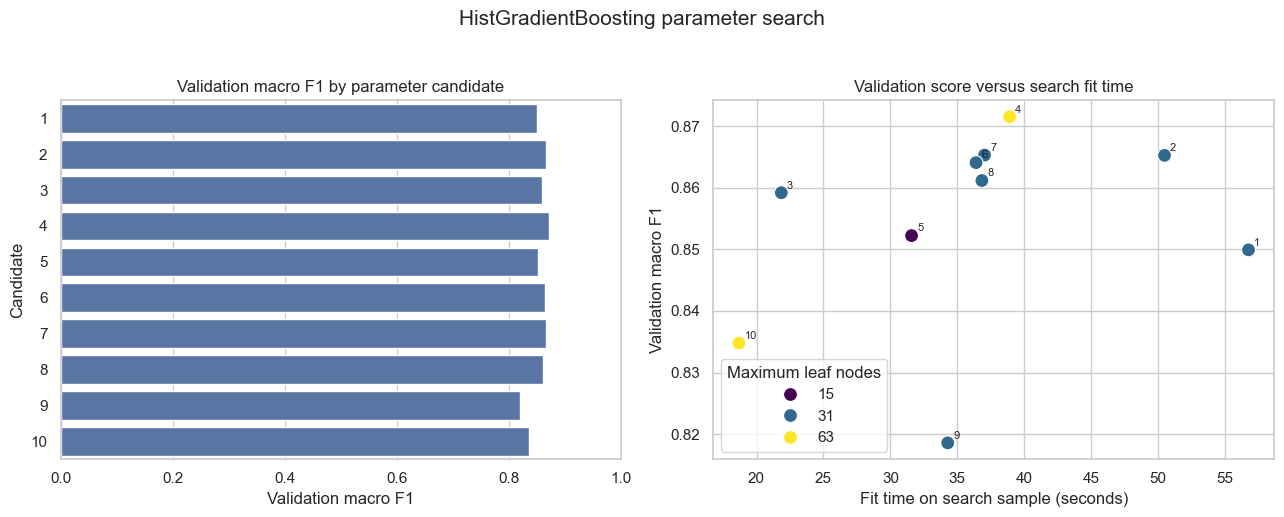

In [7]:
plot_data = search_results.sort_values('macro_f1')
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.barplot(data=plot_data, y='candidate', x='macro_f1', orient='h', color='#4C72B0', ax=axes[0])
axes[0].set_xlim(0, 1)
axes[0].set_title('Validation macro F1 by parameter candidate')
axes[0].set_xlabel('Validation macro F1')
axes[0].set_ylabel('Candidate')

sns.scatterplot(data=search_results, x='fit_seconds', y='macro_f1', hue='max_leaf_nodes',
                palette='viridis', s=100, ax=axes[1])
for _, row in search_results.iterrows():
    axes[1].annotate(int(row['candidate']), (row['fit_seconds'], row['macro_f1']),
                     xytext=(4, 3), textcoords='offset points', fontsize=8)
axes[1].set_title('Validation score versus search fit time')
axes[1].set_xlabel('Fit time on search sample (seconds)')
axes[1].set_ylabel('Validation macro F1')
axes[1].legend(title='Maximum leaf nodes')

fig.suptitle('HistGradientBoosting parameter search', fontsize=15, y=1.03)
plt.tight_layout(); plt.show()


## 7. Refit the winning configuration on the full first 80%

The final test period has not influenced parameter selection. It is scored only once below.


In [8]:
tuned_model = HistGradientBoostingClassifier(
    **best_params,
    class_weight='balanced',
    early_stopping=False,
    random_state=RS,
)

start = time.perf_counter()
tuned_model.fit(Xall[final_train_idx], yall[final_train_idx])
final_fit_seconds = time.perf_counter() - start

start = time.perf_counter()
test_pred = tuned_model.predict(Xall[test_idx])
final_predict_seconds = time.perf_counter() - start

precision, recall, f1, support = precision_recall_fscore_support(
    yall[test_idx], test_pred,
    labels=encoder.transform(LABELS), zero_division=0
)

per_class = pd.DataFrame({
    'class': LABELS,
    'precision': precision,
    'recall': recall,
    'f1': f1,
    'support': support,
})
per_class.to_csv(f'{RESULTS_DIR}/04_tuned_per_class_metrics.csv', index=False)

tuned_summary = pd.DataFrame([{
    'split': 'time-ordered',
    'model': 'HistGB tuned',
    'selected_candidate': best_candidate,
    'macro_precision': precision.mean(),
    'macro_recall': recall.mean(),
    'macro_f1': f1.mean(),
    'weighted_f1': np.average(f1, weights=support),
    'attack_macro_f1': f1[1:].mean(),
    'fit_seconds': final_fit_seconds,
    'predict_seconds': final_predict_seconds,
    **best_params,
}])
tuned_summary.to_csv(f'{RESULTS_DIR}/04_tuned_summary.csv', index=False)

display(tuned_summary.round(4))
display(per_class.round(4))


,split,model,selected_candidate,macro_precision,macro_recall,macro_f1,weighted_f1,attack_macro_f1,fit_seconds,predict_seconds,learning_rate,max_iter,max_leaf_nodes,max_depth,min_samples_leaf,l2_regularization
0,time-ordered,HistGB tuned,4,0.933,0.913,0.9199,0.9904,0.9147,226.9463,13.2379,0.05,250,63,None,20,0.1


,class,precision,recall,f1,support
0,BENIGN,0.9990,0.9973,0.9981,286990
1,Botnet,1.0000,1.0000,1.0000,148
2,DDoS,1.0000,0.9989,0.9994,19029
3,DoS GoldenEye,1.0000,1.0000,1.0000,1514
4,DoS Hulk,1.0000,1.0000,1.0000,31694
5,DoS Slowhttptest,0.3366,0.3937,0.3629,348
6,DoS Slowloris,0.9072,0.6334,0.7460,772
7,FTP-Patator,1.0000,1.0000,1.0000,795
8,Heartbleed,1.0000,1.0000,1.0000,3
9,Infiltration,1.0000,1.0000,1.0000,8


## 8. Compare tuned and base models

The original notebook 02 results are loaded from `02_summary.csv`. Macro F1 remains the primary measure because every class receives equal weight.


,model,macro_f1,weighted_f1,attack_macro_f1
1,HistGB,0.9236,0.9907,0.9186
6,HistGB tuned,0.9199,0.9904,0.9147
2,LightGBM,0.9182,0.9894,0.9129
5,XGBoost,0.9108,0.9910,0.9051
0,ExtraTrees,0.8924,0.9900,0.8853
4,RandomForest,0.8908,0.9881,0.8836
3,LogReg (baseline),0.7278,0.9841,0.7101


Base HistGB time-ordered macro F1:  0.9236
Tuned HistGB time-ordered macro F1: 0.9199
Absolute change: -0.0037


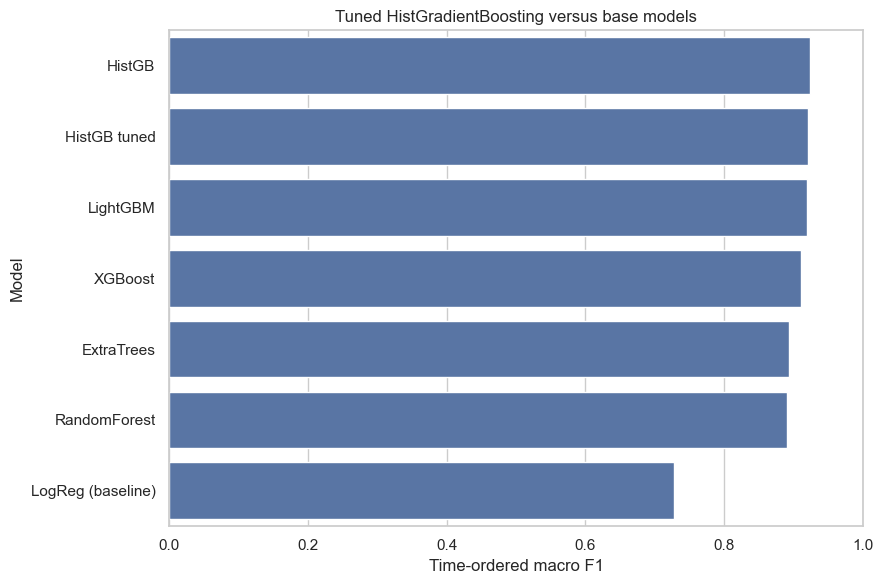

In [9]:
base = pd.read_csv(f'{RESULTS_DIR}/02_summary.csv')
base_time = base[base['split'] == 'time-ordered'][
    ['model', 'macro_f1', 'weighted_f1', 'attack_macro_f1']
].copy()
tuned_compare = tuned_summary[['model', 'macro_f1', 'weighted_f1', 'attack_macro_f1']]
comparison = pd.concat([base_time, tuned_compare], ignore_index=True).sort_values('macro_f1', ascending=False)

base_histgb = float(base_time.loc[base_time['model'] == 'HistGB', 'macro_f1'].iloc[0])
tuned_score = float(tuned_summary['macro_f1'].iloc[0])
improvement = tuned_score - base_histgb

display(comparison.round(4))
print(f'Base HistGB time-ordered macro F1:  {base_histgb:.4f}')
print(f'Tuned HistGB time-ordered macro F1: {tuned_score:.4f}')
print(f'Absolute change: {improvement:+.4f}')

fig, ax = plt.subplots(figsize=(9, 6))
sns.barplot(data=comparison, y='model', x='macro_f1', color='#4C72B0', ax=ax)
ax.set_xlim(0, 1)
ax.set_xlabel('Time-ordered macro F1')
ax.set_ylabel('Model')
ax.set_title('Tuned HistGradientBoosting versus base models')
plt.tight_layout(); plt.show()


## 9. Per-class change from the base HistGradientBoosting model

The base per-class metrics are loaded from notebook 02. Positive values indicate that tuning improved the class F1 on the same test period.


,class,precision,recall,f1,support,base_f1,f1_change
5,DoS Slowhttptest,0.3366,0.3937,0.3629,348,0.4193,-0.0564
10,Infiltration - Portscan,0.8198,0.9409,0.8762,8236,0.8801,-0.0039
11,Portscan,0.9283,0.9014,0.9146,18124,0.9172,-0.0025
0,BENIGN,0.9990,0.9973,0.9981,286990,0.9982,-0.0000
1,Botnet,1.0000,1.0000,1.0000,148,1.0000,0.0000
6,DoS Slowloris,0.9072,0.6334,0.7460,772,0.7460,0.0000
7,FTP-Patator,1.0000,1.0000,1.0000,795,1.0000,0.0000
8,Heartbleed,1.0000,1.0000,1.0000,3,1.0000,0.0000
9,Infiltration,1.0000,1.0000,1.0000,8,1.0000,0.0000
13,Web Attack - Brute Force,0.9375,1.0000,0.9677,15,0.9677,0.0000


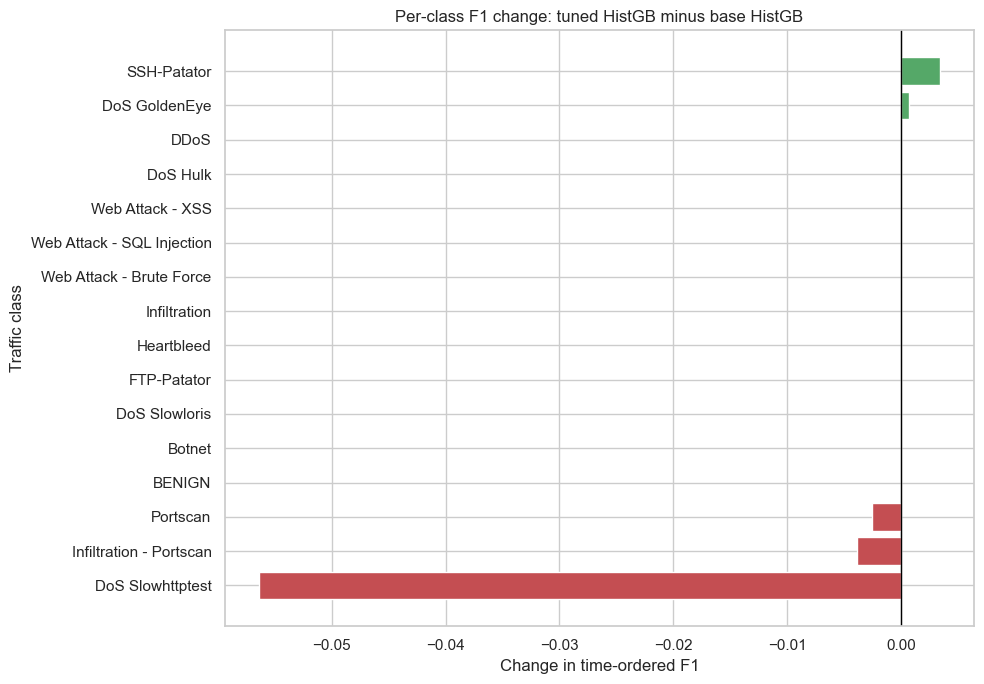

In [10]:
base_class = pd.read_csv(f'{RESULTS_DIR}/02_per_class_metrics.csv')
base_class = base_class[(base_class['split'] == 'time-ordered') & (base_class['model'] == 'HistGB')]
class_change = per_class.merge(
    base_class[['class', 'f1']].rename(columns={'f1': 'base_f1'}),
    on='class', how='left'
)
class_change['f1_change'] = class_change['f1'] - class_change['base_f1']
display(class_change.sort_values('f1_change').round(4))

plot_change = class_change.sort_values('f1_change')
colors = np.where(plot_change['f1_change'] >= 0, '#55A868', '#C44E52')
fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(plot_change['class'], plot_change['f1_change'], color=colors)
ax.axvline(0, color='black', linewidth=1)
ax.set_xlabel('Change in time-ordered F1')
ax.set_ylabel('Traffic class')
ax.set_title('Per-class F1 change: tuned HistGB minus base HistGB')
plt.tight_layout(); plt.show()


## 10. Confusion matrix for the tuned model


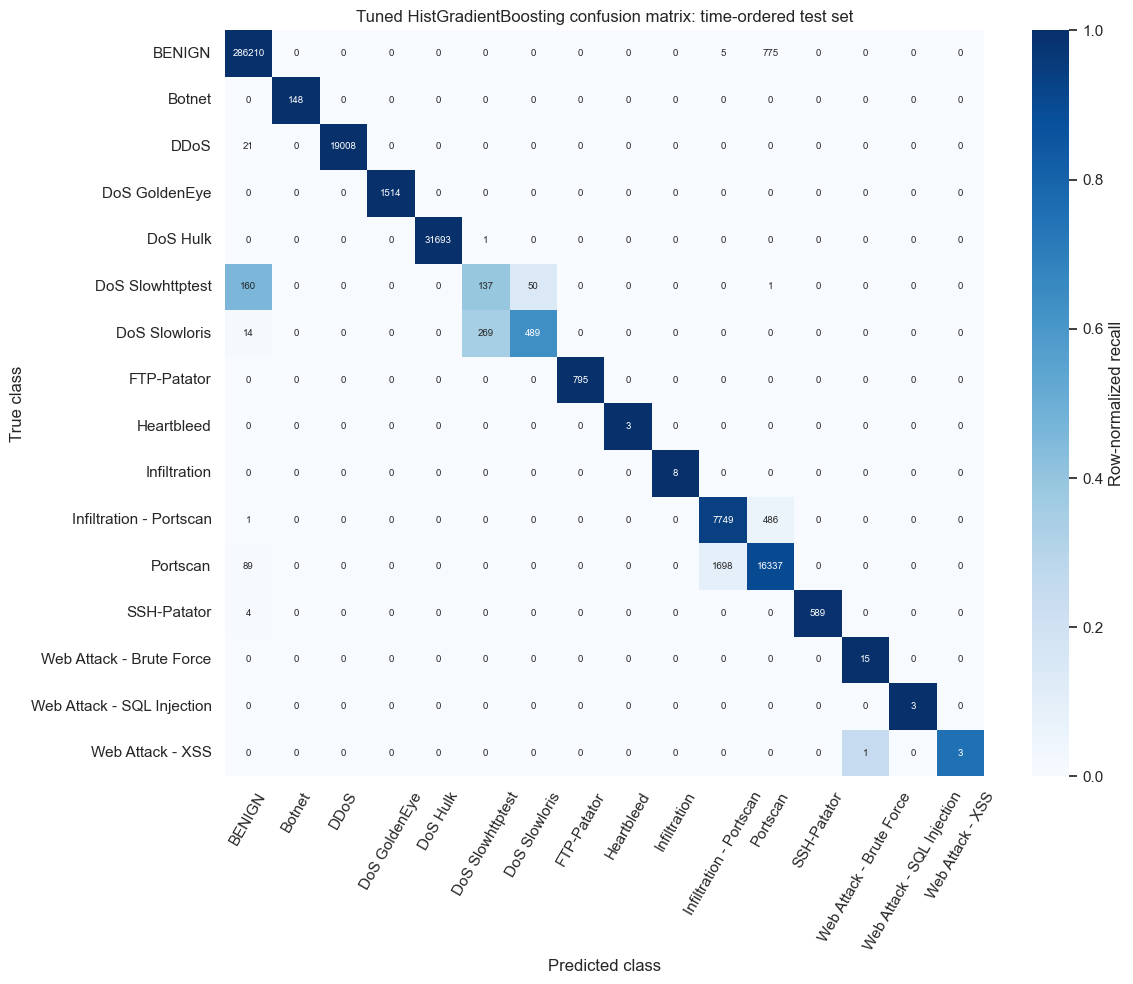

In [11]:
matrix = confusion_matrix(yall[test_idx], test_pred, labels=encoder.transform(LABELS))
normalized = matrix / np.maximum(matrix.sum(axis=1, keepdims=True), 1)

fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(
    normalized, annot=matrix, fmt='d', cmap='Blues', vmin=0, vmax=1,
    xticklabels=LABELS, yticklabels=LABELS,
    annot_kws={'fontsize': 7}, cbar_kws={'label': 'Row-normalized recall'}, ax=ax
)
ax.set_xlabel('Predicted class')
ax.set_ylabel('True class')
ax.set_title('Tuned HistGradientBoosting confusion matrix: time-ordered test set')
ax.tick_params(axis='x', labelrotation=60)
ax.tick_params(axis='y', labelrotation=0)
plt.tight_layout(); plt.show()


## 11. Detailed classification report


In [12]:
print(classification_report(
    yall[test_idx], test_pred,
    labels=encoder.transform(LABELS),
    target_names=LABELS,
    digits=4, zero_division=0,
))


                            precision    recall  f1-score   support

                    BENIGN     0.9990    0.9973    0.9981    286990
                    Botnet     1.0000    1.0000    1.0000       148
                      DDoS     1.0000    0.9989    0.9994     19029
             DoS GoldenEye     1.0000    1.0000    1.0000      1514
                  DoS Hulk     1.0000    1.0000    1.0000     31694
          DoS Slowhttptest     0.3366    0.3937    0.3629       348
             DoS Slowloris     0.9072    0.6334    0.7460       772
               FTP-Patator     1.0000    1.0000    1.0000       795
                Heartbleed     1.0000    1.0000    1.0000         3
              Infiltration     1.0000    1.0000    1.0000         8
   Infiltration - Portscan     0.8198    0.9409    0.8762      8236
                  Portscan     0.9283    0.9014    0.9146     18124
               SSH-Patator     1.0000    0.9933    0.9966       593
  Web Attack - Brute Force     0.9375    1.0000

## 12. Interpretation

The search selected **candidate 4**: `learning_rate=0.05`, `max_iter=250`, `max_leaf_nodes=63`, `max_depth=None`, `min_samples_leaf=20`, and `l2_regularization=0.1`. It achieved **0.8715 validation macro F1**.

After refitting on the complete first 80% of each class, the tuned model achieved **0.9199 macro F1** on the untouched final 20%. The original HistGradientBoosting model scored **0.9236**, so tuning changed test macro F1 by **-0.0037**. The original configuration should therefore remain the preferred model.

This negative result is informative: better performance on one validation period does not guarantee better performance on a later test period, particularly when several rare attack classes have very small support. A stronger follow-up would repeat selection over multiple temporal validation folds and then test cross-year transfer to compatible CSE-CIC-IDS2018 labels.
